# Filter cost study: gap vs overlap

Which input hurts a Stetcu–Baroni cosine filter more: a small spectral **gap** Δ or a small trial **overlap** γ?

* **A. Filter only, Hamiltonian- and trial-agnostic.** The spectrum is scaled to [0, 1] with E0 at 0 and every other level in [Δ, 1]; the trial is arbitrary with ground-state weight γ. With no Hamiltonian, the filter must work for *any* placement of the excited weight, so its cost is set by its worst case over the stop band. Cost = total evolution time T (units of 1/‖H‖) and number of pulses. No Trotter.
* **B. Amplitude amplification (AA)**, explained and simulated: how it turns the 1/p repeat-until-success overhead into ~1/√p.
* **C. Measured costs on the J1–J2 chain.** The gap is set by dimerisation δ, the overlap by a staggered-Rz layer ε. The filter length and Trotter steps are the cheapest that *measurably* reach 1−F ≤ ε in simulation. Costs are in CNOTs, with repeat-until-success and with AA, at N = 8, 10, 12, and are combined with the natural gap(N) and γ(N) of the chain up to N = 48.

Runtime: A ≈ 10 s (the optimized schedule is off by default: minutes), B ≈ 1 s, C ≈ 15 min (N = 12 is ~11 min; the maps are cached to `measured_maps/`).

In [1]:
import os, sys, time, json, glob
sys.path.insert(0, os.path.abspath(".."))          # j1j2_filter/, so `import sbpipe` finds j1j2_filter/sbpipe
import numpy as np
import matplotlib.pyplot as plt
import sbpipe
from sbpipe import design as D

EPS = 1e-2          # target infidelity 1 - F
J1, J2 = 1.0, 0.2411

## A. Filter-only cost, agnostic

For a trial with ground weight γ and a filter with stop-band suppression η = sup_{E∈[Δ,1]} |F(E)| / F(0), the worst-case infidelity after filtering is
$$1-F \le \frac{(1-\gamma)\,\eta^2}{\gamma + (1-\gamma)\,\eta^2},$$
attained when all the excited weight sits where |F| is largest. So the agnostic requirement is $\eta \le \eta^*(\gamma,\varepsilon)=\sqrt{\varepsilon\gamma/((1-\gamma)(1-\varepsilon))}$, and the filter length needed depends on γ only through $\log(1/\eta^*)\approx \tfrac12\log\frac{1}{\varepsilon\gamma}$. Each schedule turns (Δ, η*) into a length:

* **dyadic** (Stetcu–Baroni–Carlson ladder): T ≈ (e/Δ) ln(1/η*)
* **uniform** cos^m: T ≈ 2 ln(1/η*)/(π Δ²)
* **optimized** (minimax phases, sbpipe/floor): shorter, but trades away ground-state weight (F(0)² < 1)

The success probability of one attempt is p = γ F(0)² + (excited leakage) ≈ γ F(0)².

In [2]:
DELTAS = np.geomspace(0.003, 0.3, 11)                 # scaled gap
GAMMAS = np.array([0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 0.95])
SCHEDULES = ("dyadic", "uniform")                     # add "optimized" for the minimax design (slow: ~1 min/point)

def aa_cost(c_attempt, p):
    # Expected cost per success with amplitude amplification (B): k Grover iterations, (2k+1) uses of the circuit,
    # success sin^2((2k+1) theta), sin theta = sqrt(p). Falls back to plain repetition when k = 0.
    p = np.asarray(p, float)
    th = np.arcsin(np.sqrt(np.clip(p, 1e-300, 1)))
    k = np.maximum(0, np.round(np.pi / (4 * th) - 0.5))
    return c_attempt * (2 * k + 1) / np.sin((2 * k + 1) * th) ** 2

agn = {}
for sched in SCHEDULES:
    T = np.full((len(DELTAS), len(GAMMAS)), np.nan); m = T.copy(); fp = T.copy()
    for i, d in enumerate(DELTAS):
        for j, g in enumerate(GAMMAS):
            des = D.design_filter(sched, d, 0.0, EPS, g)
            if des is not None and des.m > 0:
                T[i, j], m[i, j], fp[i, j] = des.T, des.m, des.f_pass
    p = GAMMAS[None, :] * fp ** 2
    agn[sched] = dict(T=T, m=m, p=p, T_rus=T / p, T_aa=aa_cost(T, p))

def fit2(Z, x=DELTAS, y=GAMMAS):
    # ln Z = c + a ln(1/x) + b ln(1/y)
    X = np.array([[1, -np.log(a), -np.log(b)] for a in x for b in y]); z = np.log(Z.ravel()); ok = np.isfinite(z)
    c = np.linalg.lstsq(X[ok], z[ok], rcond=None)[0]
    return c[1], c[2]

print(f"{'schedule':9s} {'cost':16s} {'Delta exp':>10s} {'gamma exp':>10s}   halve Delta / halve gamma")
for sched, r in agn.items():
    for key, lab in (("T", "T per attempt"), ("T_rus", "T per success RUS"), ("T_aa", "T per success AA")):
        a, b = fit2(r[key])
        print(f"{sched:9s} {lab:16s} {a:10.2f} {b:10.2f}   x{2**a:.2f} / x{2**b:.2f}")

schedule  cost              Delta exp  gamma exp   halve Delta / halve gamma
dyadic    T per attempt          1.05       0.26   x2.07 / x1.20
dyadic    T per success RUS       1.05       1.26   x2.07 / x2.40
dyadic    T per success AA       1.05       0.84   x2.07 / x1.78
uniform   T per attempt          1.96       0.30   x3.88 / x1.23
uniform   T per success RUS       1.96       1.30   x3.88 / x2.46
uniform   T per success AA       1.96       0.87   x3.88 / x1.83


In [3]:
# --- test A ---
r = agn["dyadic"]
a_T, b_T = fit2(r["T"])
assert 0.9 < a_T < 1.2, "dyadic length should scale ~ 1/Delta"
assert b_T < 0.5, "per-attempt length should depend only weakly (logarithmically) on gamma"
# the gamma dependence is logarithmic: T at fixed Delta is linear in log(1/(eps*gamma)) to within the integer steps
i = len(DELTAS) // 2
slope = np.polyfit(np.log(1 / (EPS * GAMMAS)), r["T"][i], 1)[0]
assert slope > 0
# worst-case check of the agnostic bound on one design: put all excited weight at argmax |F| on the stop band
d, g = DELTAS[i], 0.3
des = D.design_filter("dyadic", d, 0.0, EPS, g)
E = np.linspace(d, 1, 200001); F = np.abs(des.values(E)); Emax = E[np.argmax(F)]
F0, Fw = abs(des.values(np.array([0.0]))[0]), F.max()
worst = (1 - g) * Fw ** 2 / (g * F0 ** 2 + (1 - g) * Fw ** 2)
assert worst <= EPS, f"worst-case infidelity {worst:.3g} > eps"
print(f"✓ dyadic T ~ Delta^-{a_T:.2f} gamma^-{b_T:.2f}; worst-case 1-F {worst:.2e} <= {EPS} (excited weight at E={Emax:.3f})")

✓ dyadic T ~ Delta^-1.05 gamma^-0.26; worst-case 1-F 2.50e-04 <= 0.01 (excited weight at E=0.984)


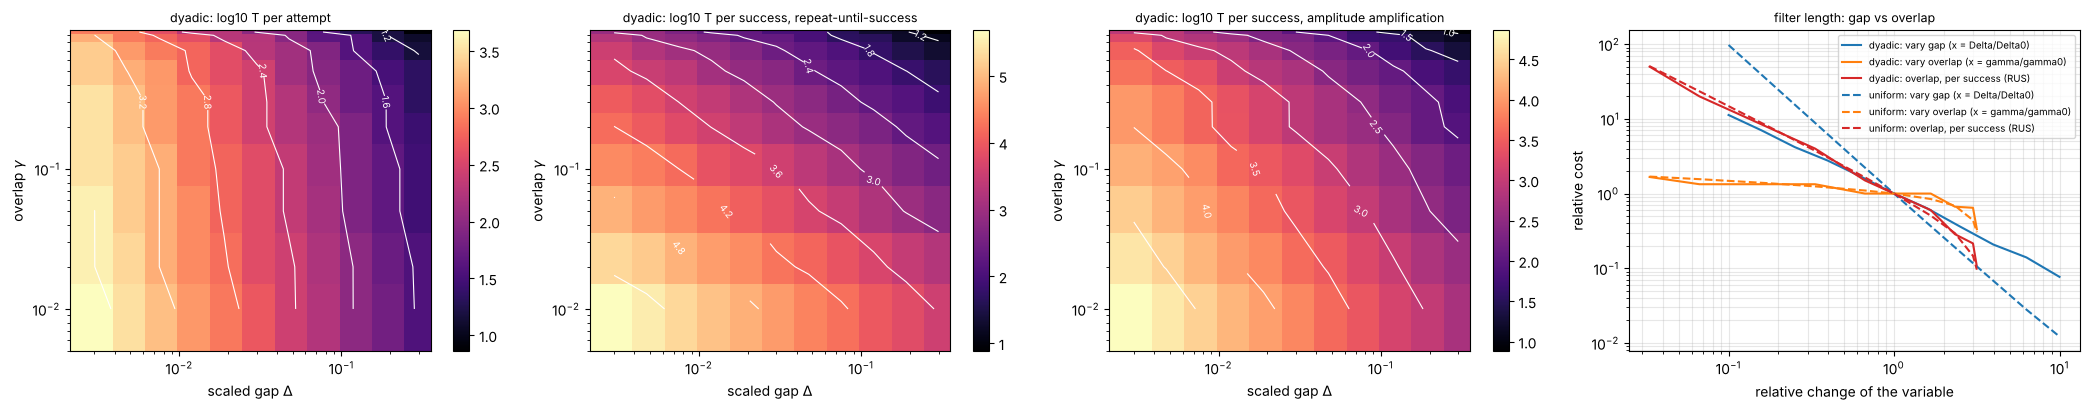

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(21, 4.2))
r = agn["dyadic"]
for a, (key, title) in zip(ax[:3], (("T", "log10 T per attempt"), ("T_rus", "log10 T per success, repeat-until-success"),
                                    ("T_aa", "log10 T per success, amplitude amplification"))):
    Z = np.log10(r[key]).T
    mesh = a.pcolormesh(DELTAS, GAMMAS, Z, shading="nearest", cmap="magma"); fig.colorbar(mesh, ax=a)
    cs = a.contour(DELTAS, GAMMAS, Z, colors="w", linewidths=0.8); a.clabel(cs, fmt="%.1f", fontsize=7)
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel(r"scaled gap $\Delta$"); a.set_ylabel(r"overlap $\gamma$")
    a.set_title(f"dyadic: {title}", fontsize=9)
for sched, ls in (("dyadic", "-"), ("uniform", "--")):
    rr = agn[sched]; j = list(GAMMAS).index(0.3); i = len(DELTAS) // 2
    ax[3].loglog(DELTAS / DELTAS[i], rr["T"][:, j] / rr["T"][i, j], ls, color="C0", label=f"{sched}: vary gap (x = Delta/Delta0)")
    ax[3].loglog(GAMMAS / GAMMAS[j], rr["T"][i] / rr["T"][i, j], ls, color="C1", label=f"{sched}: vary overlap (x = gamma/gamma0)")
    ax[3].loglog(GAMMAS / GAMMAS[j], rr["T_rus"][i] / rr["T_rus"][i, j], ls, color="C3", label=f"{sched}: overlap, per success (RUS)")
ax[3].set_xlabel("relative change of the variable"); ax[3].set_ylabel("relative cost"); ax[3].legend(fontsize=7)
ax[3].grid(alpha=0.3, which="both"); ax[3].set_title("filter length: gap vs overlap", fontsize=9)
fig.tight_layout(); plt.show()

**Reading A.** Inside the filter the gap dominates: halving Δ doubles T (dyadic) or quadruples it (uniform), while halving γ adds only ~20 % because γ enters through log(1/(εγ)). The overlap becomes as costly as the gap only through the *success probability*: with repeat-until-success the expected cost carries an extra 1/γ; with amplitude amplification only ~1/√γ.

## B. Amplitude amplification

**The problem.** One filter attempt is a unitary circuit $A$ (trial preparation $U_\psi$, then the filter with its ancilla):
$$A\,|0\rangle_a|0\rangle = \sqrt{p}\;|0\rangle_a|\phi_{\rm good}\rangle + \sqrt{1-p}\;|1\rangle_a|\phi_{\rm bad}\rangle ,$$
where "good" means the ancilla reads 0 and $|\phi_{\rm good}\rangle$ is the filtered (≈ ground) state. Measuring and repeating until success costs $1/p$ attempts on average, and $p\approx\gamma F(0)^2$, so this is where the $1/\gamma$ comes from.

**The fix (Grover / Brassard–Høyer–Mosca–Tapp).** Define two reflections
* $S_{\rm good} = I - 2\,|0\rangle\langle 0|_a\otimes I$: a $Z$ on the ancilla (flips the sign of the good part),
* $S_0 = I - 2\,|0\rangle\langle0|$ on everything (reflection about the all-zero start state),

and the iterate $Q = -A\,S_0\,A^\dagger\,S_{\rm good}$. The state stays in the 2-D plane spanned by the good and bad parts; with $\sin\theta=\sqrt p$, each $Q$ rotates it by $2\theta$:
$$Q^k A|0\rangle = \sin((2k+1)\theta)\,|{\rm good}\rangle + \cos((2k+1)\theta)\,|{\rm bad}\rangle .$$
Choosing $k\approx \frac{\pi}{4\theta}-\frac12$ makes the success probability ≈ 1 after $2k+1\approx \frac{\pi}{2\sqrt p}$ uses of $A$ or $A^\dagger$ (each iteration uses both), instead of $1/p$ on average. For $p=0.01$ that is ~16 instead of 100.

**What it needs.**
1. The whole attempt must be **coherent**: no mid-circuit measurement or early abort inside $A$, and the trial preparation $U_\psi$ must be a unitary circuit we can invert (true for an MPS/staircase trial, not for a trial that is itself post-selected or measured).
2. $A^\dagger$: the same gates in reverse, so the same CNOT count per use.
3. **Knowing $p$** to pick $k$. Overshooting rotates past the good state. If $p$ is uncertain, use *fixed-point* AA (Yoder–Low–Chuang 2014) or the QSVT version (Gilyén et al. 2019): it can't overshoot, at a cost of ~log(1/δ) more queries for failure probability δ.
4. The reflection $S_0$ is a multi-controlled Z on N+1 qubits: O(N) gates, negligible next to the filter.

It does **not** help the filter length T (part A): it only removes the 1/p repetition overhead. And it does not fix a bad trial in a different sense: if γ is exponentially small, √(1/γ) is still exponential.

In [5]:
# Simulate AA exactly on a small example: a random 'filter' F (Hermitian contraction) on a trial |psi>,
# block-encoded with one ancilla: A = [[F, sqrt(1-F^2)], [sqrt(1-F^2), -F]] (U_psi), good = ancilla 0.
rng = np.random.default_rng(1)
dim = 64
H = rng.normal(size=(dim, dim)); H = (H + H.T) / 2; w, V = np.linalg.eigh(H)
es = (w - w[0]) / (w[-1] - w[0])                                         # scaled spectrum, gap = es[1]
f = np.exp(-(es / 0.01) ** 2)                                            # a sharp filter, F(0) = 1, |F| <= 1
F = V @ np.diag(f) @ V.T
S = V @ np.diag(np.sqrt(1 - f ** 2)) @ V.T                               # sqrt(1 - F^2)
Ublk = np.block([[F, S], [S, -F]])                                       # unitary block encoding of F
assert np.allclose(Ublk @ Ublk.T, np.eye(2 * dim), atol=1e-10)
gamma = 0.02
psi = np.sqrt(gamma) * V[:, 0] + np.sqrt(1 - gamma) * V[:, 1:6] @ np.ones(5) / np.sqrt(5)
# U_psi: any unitary with U_psi |0> = psi (Householder reflection)
e0 = np.zeros(dim); e0[0] = 1
u = psi - e0; Upsi = np.eye(dim) - 2 * np.outer(u, u) / (u @ u) if np.linalg.norm(u) > 1e-12 else np.eye(dim)
A = Ublk @ np.kron(np.eye(2), Upsi)                                      # |anc, sys>
start = np.zeros(2 * dim); start[0] = 1
S_good = np.diag(np.r_[-np.ones(dim), np.ones(dim)])                     # flip the ancilla-0 (good) block
S_0 = np.eye(2 * dim) - 2 * np.outer(start, start)
Q = -A @ S_0 @ A.T @ S_good

v = A @ start
p = float(np.sum(v[:dim] ** 2)); th = np.arcsin(np.sqrt(p))
probs = []
for k in range(12):
    probs.append(float(np.sum(v[:dim] ** 2))); v = Q @ v
k_opt = int(max(0, round(np.pi / (4 * th) - 0.5)))
pred = [np.sin((2 * k + 1) * th) ** 2 for k in range(12)]
good = (A @ start)[:dim]; good /= np.linalg.norm(good)
vk = np.linalg.matrix_power(Q, k_opt) @ A @ start; gk = vk[:dim] / np.linalg.norm(vk[:dim])

print(f"single attempt: p = {p:.4f}  -> repeat-until-success needs 1/p = {1/p:.1f} attempts")
print(f"AA: theta = {th:.4f}, k = {k_opt} iterations = {2*k_opt+1} uses of A,  success {probs[k_opt]:.4f}")
print(f"expected uses per success: RUS {1/p:.1f}   AA {(2*k_opt+1)/probs[k_opt]:.1f}   (pi/(2 sqrt p) = {np.pi/(2*np.sqrt(p)):.1f})")

single attempt: p = 0.0200  -> repeat-until-success needs 1/p = 50.0 attempts
AA: theta = 0.1419, k = 5 iterations = 11 uses of A,  success 0.9999
expected uses per success: RUS 50.0   AA 11.0   (pi/(2 sqrt p) = 11.1)


✓ sin^2((2k+1) theta) law exact; post-selected state unchanged; AA 11.0 vs RUS 50.0 uses


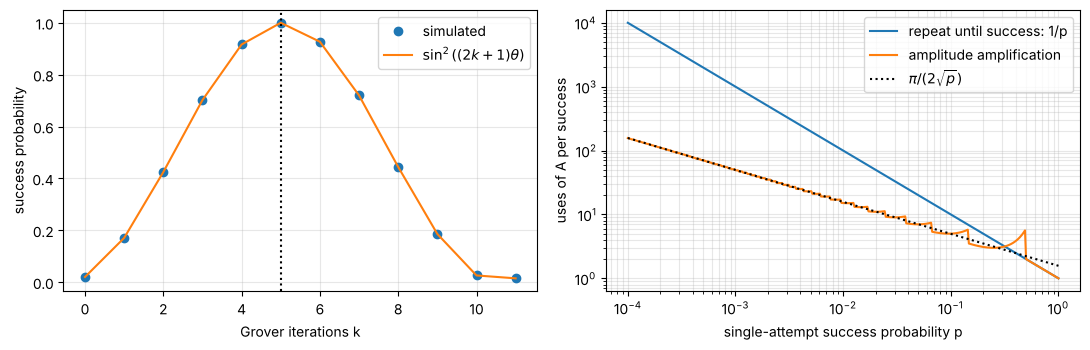

In [6]:
# --- test B ---
assert np.allclose(probs, pred, atol=1e-10), "success probabilities do not follow sin^2((2k+1) theta)"
assert probs[k_opt] > 0.9
assert abs(abs(np.vdot(good, gk)) - 1) < 1e-10, "AA changed the post-selected state"
assert (2 * k_opt + 1) / probs[k_opt] < 0.5 / p
print(f"✓ sin^2((2k+1) theta) law exact; post-selected state unchanged; AA {(2*k_opt+1)/probs[k_opt]:.1f} vs RUS {1/p:.1f} uses")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(range(12), probs, "o", label="simulated"); ax[0].plot(range(12), pred, "-", label=r"$\sin^2((2k+1)\theta)$")
ax[0].axvline(k_opt, color="k", ls=":"); ax[0].set_xlabel("Grover iterations k"); ax[0].set_ylabel("success probability"); ax[0].legend()
pp = np.geomspace(1e-4, 1, 400)
ax[1].loglog(pp, 1 / pp, label="repeat until success: 1/p")
ax[1].loglog(pp, aa_cost(1.0, pp), label="amplitude amplification")
ax[1].loglog(pp, np.pi / (2 * np.sqrt(pp)), "k:", label=r"$\pi/(2\sqrt{p})$")
ax[1].set_xlabel("single-attempt success probability p"); ax[1].set_ylabel("uses of A per success"); ax[1].legend()
for a in ax: a.grid(alpha=0.3, which="both")
fig.tight_layout(); plt.show()

## C. Measured cost on the J1–J2 chain

* **Gap knob:** dimerisation, J1 bonds (1 ± δ); δ solved per target gap by ED. Keeps SU(2) (singlet ground state, triplet first excitation); δ < 0 closes the gap (weak end bonds), δ > 0 opens it.
* **Overlap knob:** one layer of staggered Rz, $e^{-i\epsilon\sum_i(-1)^iZ_i}$, on the exact ground state; ε solved per target γ. It conserves S^z and moves the missing weight onto the triplets (including E1), the hard case for the filter.
* **Measured cost:** dyadic ladder (K rungs, r repeats) with n second-order Strang steps per τ. One Strang step's eigenphases make every Trotterised (K, r) exact and instant, so (K, r, n) are optimised jointly. A choice counts only if simulated 1−F ≤ ε, and still does at the next finer n. Costs are CNOT per attempt (sbpipe's bond-compiled count) per success, with repeat-until-success (÷p) or AA (B).
* Everything runs in the S^z = 0 sector, where a Heisenberg bond is J/4(2 SWAP − 1): exact permutations. This is checked against sbpipe's product formula below.

In [7]:
import time
from itertools import combinations
import numpy as np
from scipy.optimize import brentq
import sbpipe
from sbpipe.resources import filter_counts

class Sector:
    """S^z = 0 sector of an N-site chain: basis, bond swaps, staggered magnetisation."""
    def __init__(self, N):
        self.N = N
        self.states = np.array(sorted(sum(1 << (N - 1 - q) for q in c) for c in combinations(range(N), N // 2)))
        self.pos = {s: k for k, s in enumerate(self.states)}
        bits = (self.states[:, None] >> (N - 1 - np.arange(N))[None, :]) & 1        # site 0 = MSB (sbpipe)
        self.M = ((1 - 2 * bits) * (-1) ** np.arange(N)).sum(1).astype(float)    # sum_i (-1)^i Z_i
        self._swap = {}
    def swap(self, i, j):
        if (i, j) not in self._swap:
            mi, mj = 1 << (self.N - 1 - i), 1 << (self.N - 1 - j)
            s = self.states
            diff = ((s & mi) > 0) != ((s & mj) > 0)
            t = np.where(diff, s ^ mi ^ mj, s)
            self._swap[(i, j)] = np.array([self.pos[x] for x in t])
        return self._swap[(i, j)]
    def dense_swap(self, i, j):
        P = np.zeros((len(self.states),) * 2); P[self.swap(i, j), np.arange(len(self.states))] = 1
        return P

def chain_bonds(N, J1, J2, delta):
    """(i, j, J) in sbpipe.j1j2_chain order (= Trotter order): J1 even, J1 odd, J2 even, J2 odd."""
    out = []
    for r, J in ((1, J1), (2, J2)):
        if J == 0:
            continue
        for par in (0, 1):
            for i in range(N - r):
                if i % 2 == par:
                    f = (1 + delta if i % 2 == 0 else 1 - delta) if r == 1 else 1.0
                    out.append((i, i + r, J * f))
    return out

def sector_H(sec, bonds):
    """H restricted to S^z = 0: sum_b J_b/4 (2 SWAP_b - 1)."""
    d = len(sec.states); H = np.zeros((d, d))
    for i, j, J in bonds:
        H += 0.5 * J * sec.dense_swap(i, j)
    return H - 0.25 * sum(J for _, _, J in bonds) * np.eye(d)

def strang(sec, bonds, v, t, k, shift, W):
    """k Strang steps of e^{-i t H_s}, H_s = (H - shift)/W, on a sector vector. Bond factor:
    exp(-i a (J/4W)(2 SWAP - 1)) = e^{i a J/4W} (cos(a J/2W) - i sin(a J/2W) SWAP); phases collected exactly."""
    dt = t / k
    c0 = (-0.25 * sum(J for _, _, J in bonds) - shift) / W           # constant part of H_s
    v = np.array(v, dtype=complex)
    seq = [(i, j, 0.5 * J / W) for i, j, J in bonds]
    half = [(np.cos(c * dt / 2), -1j * np.sin(c * dt / 2), sec.swap(i, j)) for i, j, c in seq]
    for _ in range(k):
        for a, b, p in half:
            v = a * v + b * v[p]
        for a, b, p in reversed(half):
            v = a * v + b * v[p]
    return np.exp(-1j * c0 * t) * v

def dyadic_times(delta_s, K, r):
    tau = np.pi / (1 + delta_s)
    return np.tile(tau * 2.0 ** np.arange(K), r)

class Point:
    """One (N, delta) Hamiltonian: spectrum, scaled window, ground state."""
    def __init__(self, sec, J1, J2, delta):
        self.sec, self.bonds = sec, chain_bonds(sec.N, J1, J2, delta)
        w, V = np.linalg.eigh(sector_H(sec, self.bonds))
        self.w, self.V, self.g0 = w, V, V[:, 0]
        self.gap, self.W, self.shift = w[1] - w[0], w[-1] - w[0], w[0]
        self.es = (w - w[0]) / self.W                                   # scaled spectrum, E0 -> 0, top -> 1
        self.delta_s = self.es[1]
        Hp = sbpipe.j1j2_chain(sec.N, J1=J1, J2=J2)
        self.Hs_pauli = Hp.shifted_scaled(self.shift, self.W)          # labels/groups for the gate count only

    def trial(self, eps):
        return np.exp(-1j * eps * self.sec.M) * self.g0

    def eps_for_gamma(self, target):
        gam = lambda e: abs(np.vdot(self.g0, self.trial(e))) ** 2
        es = np.linspace(0, 1.2, 1201); gs = np.array([gam(e) for e in es])
        up = np.flatnonzero(np.diff(gs) > 0); stop = up[0] if len(up) else len(es) - 1
        if not gs[stop] <= target <= 1.0:
            return None
        return brentq(lambda e: gam(e) - target, 0.0, es[stop], xtol=1e-13)

    def exact_metrics(self, psi, times):
        c = self.V.conj().T @ psi
        F = np.prod(np.cos(np.outer(self.es, times)), axis=1)
        a = F * c
        p = float(np.sum(np.abs(a) ** 2))
        return dict(p=p, infid=max(0.0, 1 - abs(a[0]) ** 2 / p))

    def trotter_metrics(self, psi, times, steps):
        v = np.array(psi, dtype=complex)
        for t, k in zip(times, steps):
            v = 0.5 * (strang(self.sec, self.bonds, v, t, int(k), self.shift, self.W)
                       + strang(self.sec, self.bonds, v, -t, int(k), self.shift, self.W))
        p = float(np.vdot(v, v).real)
        return dict(p=p, infid=max(0.0, 1 - abs(np.vdot(self.g0, v)) ** 2 / p))

N_GRID = (1, 2, 3, 4, 5, 6, 8, 10, 12, 16, 20, 24, 32, 40, 48, 64)   # Strang steps per tau (per shortest pulse)

def strang_step_matrix(pt, dt):
    """Dense one-step Strang unitary U(dt) for e^{-i dt H_s} in the sector (columns = images of basis vectors)."""
    d = len(pt.sec.states)
    return strang(pt.sec, pt.bonds, np.eye(d), dt, 1, pt.shift, pt.W)

def trotter_spectrum(pt, n):
    """Eigenphases/vectors of one Strang step with dt = tau/n. With k_i = n 2^k steps for the pulse t = tau 2^k,
    and S(-dt) = S(dt)^dagger (Strang is symmetric), a Trotterised pulse is exactly cos(k_i theta) in this basis:
    the Trotterised filter is the exact filter of the effective Hamiltonian theta/dt."""
    from scipy.linalg import schur
    tau = np.pi / (1 + pt.delta_s)
    T, Z = schur(strang_step_matrix(pt, tau / n), output="complex")
    return -np.angle(np.diag(T)), Z

def best_dyadic(theta_k, c, u, eps_target, K_max=16, r_max=200):
    """For one step size: per K the smallest r with 1-F <= eps; returns list of (K, r, p, infid).
    theta_k = phase per tau (so pulse tau 2^k has phase 2^k theta_k); c, u = trial, ground in that basis."""
    out = []
    B = np.ones_like(theta_k)
    for K in range(1, K_max + 1):
        B = B * np.cos(2.0 ** (K - 1) * theta_k)
        a = c.copy()
        for r in range(1, r_max + 1):
            a = a * B
            p = float(np.sum(np.abs(a) ** 2))
            if p < 1e-300:
                break
            inf = 1 - abs(np.vdot(u, a)) ** 2 / p
            if inf <= eps_target:
                out.append((K, r, p, inf)); break
    return out

def measured_row(pt, psis, eps_target, order=2, robust=True):
    """Measured cheapest (K, r, n) for each trial state in psis (same Hamiltonian). Cost = CNOT/attempt / p_succ.
    robust: a (K, r, n) only counts if (K, r) also meets eps at the next finer n (no lucky Trotter cancellations)."""
    spec = {n: trotter_spectrum(pt, n) for n in N_GRID}
    res = [None] * len(psis)
    for idx, n in enumerate(N_GRID):
        theta, Z = spec[n]
        theta = theta * n                                   # phase per tau
        u = Z.conj().T @ pt.g0
        n_next = N_GRID[min(idx + 1, len(N_GRID) - 1)]
        th2, Z2 = spec[n_next]; th2 = th2 * n_next; u2 = Z2.conj().T @ pt.g0
        for j, psi in enumerate(psis):
            c = Z.conj().T @ psi
            for K, r, p, inf in best_dyadic(theta, c, u, eps_target):
                if robust and n_next != n:
                    a = Z2.conj().T @ psi
                    Bk = np.prod([np.cos(2.0 ** k * th2) for k in range(K)], axis=0) ** r
                    a = a * Bk; pp = float(np.sum(np.abs(a) ** 2))
                    if pp < 1e-300 or 1 - abs(np.vdot(u2, a)) ** 2 / pp > eps_target:
                        continue
                steps = np.tile(n * 2 ** np.arange(K), r)
                cnot = filter_counts(pt.Hs_pauli, steps, order)["cnot"]
                row = dict(K=K, r=r, n=n, m=K * r, steps=int(steps.sum()), T_scaled=float(dyadic_times(pt.delta_s, K, r).sum()),
                           cnot=cnot, p_succ=p, infid=inf, cnot_exp=cnot / p)
                if res[j] is None or row["cnot_exp"] < res[j]["cnot_exp"]:
                    res[j] = row
    return [r or {} for r in res]

def delta_for_gap(sec, J1, J2, target):
    f = lambda d: Point(sec, J1, J2, d).gap - target
    return brentq(f, -0.6, 0.95, xtol=1e-9)

def measured_map(N, J1, J2, gap_targets, gamma_targets, eps_target, verbose=True):
    sec, rows, t0 = Sector(N), [], time.time()
    for gt in gap_targets:
        try:
            d = delta_for_gap(sec, J1, J2, gt)
        except ValueError:
            rows.append([dict() for _ in gamma_targets]); continue
        pt = Point(sec, J1, J2, d)
        eps_list = [pt.eps_for_gamma(gm) for gm in gamma_targets]
        psis = [pt.trial(e) if e is not None else pt.g0 for e in eps_list]
        row = measured_row(pt, psis, eps_target)
        for r_, e, psi in zip(row, eps_list, psis):
            if e is None:
                r_.clear(); continue
            r_.update(gap=pt.gap, gamma=abs(np.vdot(pt.g0, psi)) ** 2, delta=d, delta_s=pt.delta_s, W=pt.W, eps=e)
        rows.append(row)
        if verbose:
            print(f"N={N} gap {pt.gap:.4f} (delta {d:+.3f}, scaled {pt.delta_s:.4f}): done, {time.time() - t0:.0f} s",
                  flush=True)
    return rows

In [8]:
# --- test C1: the fast sector simulator equals sbpipe's Trotter, and the eigenphase route equals direct Strang ---
from sbpipe.trotter import product_formula
Nt, dt_ = 8, 0.13
sec_t = Sector(Nt); pt_t = Point(sec_t, J1, J2, dt_); psi_t = pt_t.trial(0.15)
Hfull = sbpipe.PauliSum(list(sbpipe.j1j2_chain(Nt, J1, J2).labels),
                        np.array([0.25 * J for _, _, J in pt_t.bonds for _ in range(3)]),
                        list(sbpipe.j1j2_chain(Nt, J1, J2).groups)).shifted_scaled(pt_t.shift, pt_t.W)
emb = np.zeros(2 ** Nt, complex)
def embed(v):
    x = np.zeros(2 ** Nt, complex); x[sec_t.states] = v; return x
for t_, k_ in ((0.7, 3), (-2.3, 5)):
    err = np.abs(embed(strang(sec_t, pt_t.bonds, psi_t, t_, k_, pt_t.shift, pt_t.W))
                 - product_formula(Hfull, embed(psi_t), t_, k_, 2)).max()
    assert err < 1e-12, err
n_, K_, r_ = 3, 4, 2
th_, Z_ = trotter_spectrum(pt_t, n_)
a_ = Z_ @ ((Z_.conj().T @ psi_t) * np.prod([np.cos(n_ * 2.0 ** k * th_) for k in range(K_)], axis=0) ** r_)
v_ = psi_t.astype(complex)
for t_, k_ in zip(dyadic_times(pt_t.delta_s, K_, r_), np.tile(n_ * 2 ** np.arange(K_), r_)):
    v_ = 0.5 * (strang(sec_t, pt_t.bonds, v_, t_, int(k_), pt_t.shift, pt_t.W)
                + strang(sec_t, pt_t.bonds, v_, -t_, int(k_), pt_t.shift, pt_t.W))
assert np.abs(a_ - v_).max() < 1e-12
print("✓ sector Strang == sbpipe product_formula; eigenphase filter == direct Trotterised filter")

✓ sector Strang == sbpipe product_formula; eigenphase filter == direct Trotterised filter


In [9]:
N_LIST   = (8, 10, 12)
GAPS_T   = np.geomspace(0.02, 1.5, 10)                                   # target physical gaps (J1)
GAMMAS_T = np.array([0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.98])
CACHE    = "measured_maps"
os.makedirs(CACHE, exist_ok=True)
_num = lambda x: float(x) if isinstance(x, (np.floating, np.integer)) else x
MAPS = {}
for Nm in N_LIST:
    f = os.path.join(CACHE, f"map_N{Nm}_J2{J2}_eps{EPS}.json")
    if os.path.exists(f):
        MAPS[Nm] = json.load(open(f))["rows"]; print(f"N={Nm}: loaded {f}"); continue
    MAPS[Nm] = measured_map(Nm, J1, J2, GAPS_T, GAMMAS_T, EPS, verbose=False)
    json.dump(dict(N=Nm, gaps=GAPS_T.tolist(), gammas=GAMMAS_T.tolist(),
                   rows=[[{k: _num(v) for k, v in r.items()} for r in row] for row in MAPS[Nm]]), open(f, "w"))
    print(f"N={Nm}: measured")

N=8: loaded measured_maps/map_N8_J20.2411_eps0.01.json
N=10: loaded measured_maps/map_N10_J20.2411_eps0.01.json
N=12: loaded measured_maps/map_N12_J20.2411_eps0.01.json


In [10]:
# --- test C2: every measured point meets the target, and the knobs hit their targets ---
for Nm, rows in MAPS.items():
    for row, gt in zip(rows, GAPS_T):
        for r, gm in zip(row, GAMMAS_T):
            assert r, f"N={Nm}: no feasible filter at gap {gt}, gamma {gm}"
            assert r["infid"] <= EPS + 1e-12
            assert abs(r["gap"] - gt) < 1e-6 and abs(r["gamma"] - gm) < 1e-8
print(f"✓ {sum(len(r) * len(r[0]) for r in MAPS.values())} measured points, all with 1-F <= {EPS} at the target (gap, gamma)")

✓ 330 measured points, all with 1-F <= 0.01 at the target (gap, gamma)


In [11]:
def arrays(rows, kind):
    G = np.array([[r["gap"] for r in row] for row in rows]); Y = np.array([[r["gamma"] for r in row] for row in rows])
    c = np.array([[r["cnot"] for r in row] for row in rows]); p = np.array([[r["p_succ"] for r in row] for row in rows])
    C = {"attempt": c, "rus": c / p, "aa": aa_cost(c, p)}[kind]
    return G, Y, C

def fit_powerlaw(rows, kind, gamma_max=0.95):
    # ln C = c0 + a ln(1/gap) + b ln(1/gamma) over gamma <= gamma_max (near 1 - gamma ~ eps the filter vanishes)
    G, Y, C = arrays(rows, kind)
    m = np.isfinite(C) & (Y <= gamma_max + 1e-9)
    X = np.column_stack([np.ones(m.sum()), -np.log(G[m]), -np.log(Y[m])]); y = np.log(C[m])
    coef = np.linalg.lstsq(X, y, rcond=None)[0]; res = y - X @ coef
    se = np.sqrt(np.diag(res @ res / (len(y) - 3) * np.linalg.inv(X.T @ X)))
    return dict(c0=coef[0], a=coef[1], b=coef[2], se_a=se[1], se_b=se[2], r2=1 - res @ res / np.sum((y - y.mean()) ** 2))

def knee(x, y):
    # Kneedle: max distance below the chord of the normalised decreasing curve (range-dependent by construction)
    x, y = np.asarray(x, float), np.asarray(y, float); ok = np.isfinite(y); x, y = x[ok], y[ok]
    xn = (x - x[0]) / (x[-1] - x[0]); yn = (y - y.min()) / (y.max() - y.min())
    return x[np.argmax((1 - xn) - yn)]

FITS = {kind: {Nm: fit_powerlaw(rows, kind) for Nm, rows in MAPS.items()} for kind in ("attempt", "rus", "aa")}
for kind, lab in (("attempt", "CNOT per attempt"), ("rus", "per success, RUS"), ("aa", "per success, AA")):
    for Nm, f in FITS[kind].items():
        print(f"{lab:18s} N={Nm:2d}: C ~ gap^-{f['a']:.2f}(+-{f['se_a']:.2f}) gamma^-{f['b']:.2f}(+-{f['se_b']:.2f})  R^2={f['r2']:.3f}"
              f"   halve gap x{2**f['a']:.2f}, halve gamma x{2**f['b']:.2f}")

CNOT per attempt   N= 8: C ~ gap^-1.13(+-0.03) gamma^-0.33(+-0.04)  R^2=0.925   halve gap x2.18, halve gamma x1.26
CNOT per attempt   N=10: C ~ gap^-1.12(+-0.03) gamma^-0.31(+-0.03)  R^2=0.931   halve gap x2.18, halve gamma x1.24
CNOT per attempt   N=12: C ~ gap^-1.16(+-0.03) gamma^-0.32(+-0.03)  R^2=0.948   halve gap x2.23, halve gamma x1.24
per success, RUS   N= 8: C ~ gap^-1.19(+-0.03) gamma^-1.31(+-0.03)  R^2=0.971   halve gap x2.28, halve gamma x2.49
per success, RUS   N=10: C ~ gap^-1.19(+-0.03) gamma^-1.31(+-0.03)  R^2=0.974   halve gap x2.28, halve gamma x2.47
per success, RUS   N=12: C ~ gap^-1.21(+-0.03) gamma^-1.31(+-0.03)  R^2=0.974   halve gap x2.31, halve gamma x2.48
per success, AA    N= 8: C ~ gap^-1.19(+-0.04) gamma^-0.88(+-0.04)  R^2=0.934   halve gap x2.28, halve gamma x1.84
per success, AA    N=10: C ~ gap^-1.20(+-0.04) gamma^-0.86(+-0.04)  R^2=0.940   halve gap x2.30, halve gamma x1.82
per success, AA    N=12: C ~ gap^-1.22(+-0.04) gamma^-0.87(+-0.04)  R^2=0.930   

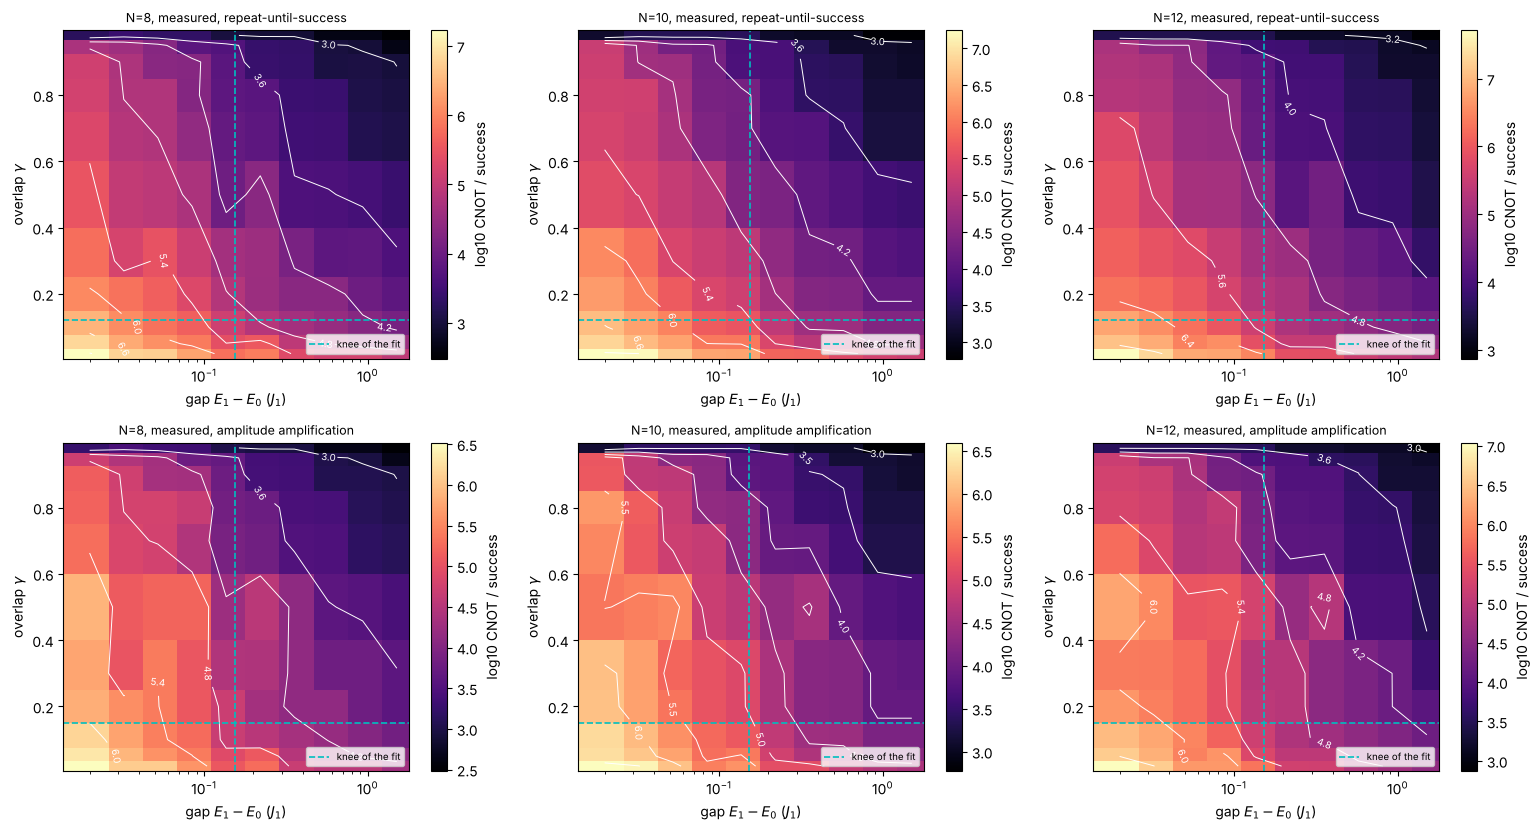

In [12]:
Ns = sorted(MAPS)
fig, ax = plt.subplots(2, len(Ns), figsize=(5.2 * len(Ns), 8.4), squeeze=False)
y_rng = np.linspace(GAMMAS_T.min(), GAMMAS_T.max(), 400); g_rng = np.geomspace(GAPS_T.min(), GAPS_T.max(), 400)
for row_ax, kind in zip(ax, ("rus", "aa")):
    for a, Nm in zip(row_ax, Ns):
        G, Y, C = arrays(MAPS[Nm], kind); f = FITS[kind][Nm]
        Z = np.log10(C).T
        mesh = a.pcolormesh(G[:, 0], Y[0], Z, shading="nearest", cmap="magma"); fig.colorbar(mesh, ax=a, label="log10 CNOT / success")
        cs = a.contour(G[:, 0], Y[0], Z, colors="w", linewidths=0.7); a.clabel(cs, fmt="%.1f", fontsize=7)
        a.axhline(knee(y_rng, y_rng ** -f["b"]), color="c", ls="--", lw=1.2, label="knee of the fit")
        a.axvline(knee(g_rng, g_rng ** -f["a"]), color="c", ls="--", lw=1.2)
        a.set_xscale("log"); a.set_xlabel(r"gap $E_1-E_0$ ($J_1$)"); a.set_ylabel(r"overlap $\gamma$")
        a.set_title(f"N={Nm}, measured, {'repeat-until-success' if kind == 'rus' else 'amplitude amplification'}", fontsize=9)
        a.legend(loc="lower right", fontsize=7)
fig.tight_layout(); plt.show()

### Scaling with N: which knob degrades faster on the real chain

The natural J1–J2 chain (δ = 0, no ε) has a gap that closes as a power of N, and a fixed-χ trial whose overlap decays exponentially. Combining those (DMRG, N = 8–48, from `sbpipe_study/results/cache`) with the measured exponents gives each knob's contribution to ln(cost) as N grows.

natural gap ~ N^-0.92
RUS  chi=2: ln-cost added N=8->48: gap 1.99, overlap 2.04; overlap grows faster per site from N ~ 24
RUS  chi=4: ln-cost added N=8->48: gap 1.99, overlap 0.11; overlap grows faster per site from N ~ None
RUS  chi=8: ln-cost added N=8->48: gap 1.99, overlap 0.01; overlap grows faster per site from N ~ None
AA   chi=2: ln-cost added N=8->48: gap 2.01, overlap 1.36; overlap grows faster per site from N ~ 40
AA   chi=4: ln-cost added N=8->48: gap 2.01, overlap 0.07; overlap grows faster per site from N ~ None
AA   chi=8: ln-cost added N=8->48: gap 2.01, overlap 0.00; overlap grows faster per site from N ~ None


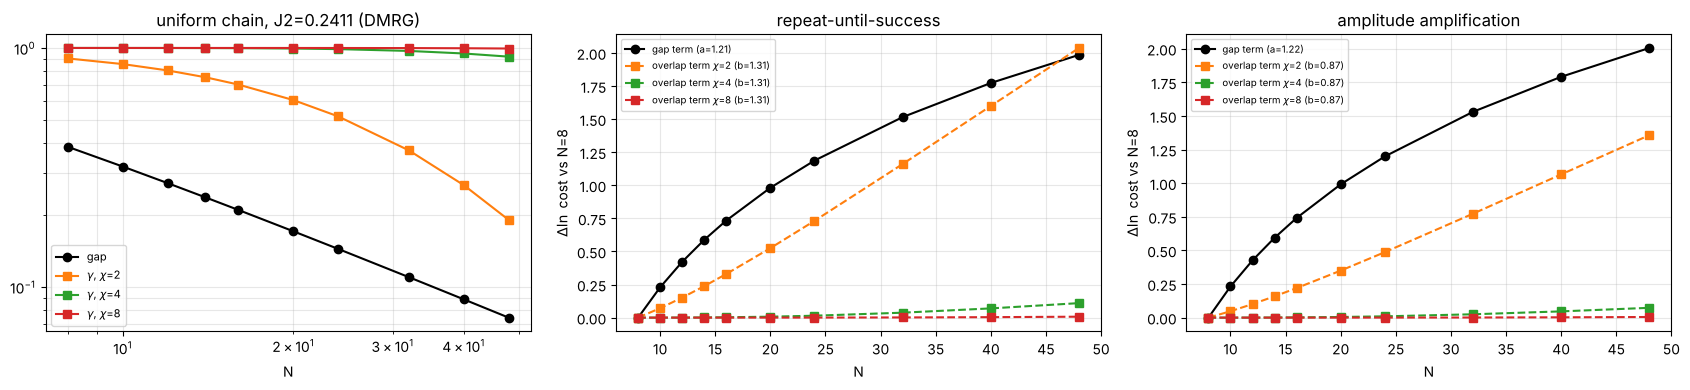

In [13]:
nat = {}
for fpath in glob.glob("../sbpipe_study/results/cache/N*_J2*.json"):
    d = json.load(open(fpath))
    if abs(d["J2"] - J2) < 1e-9:
        nat[d["N"]] = dict(gap=d["est"]["E1"] - d["est"]["E0"], **{f"g{k}": v["gamma"] for k, v in d["ansatz"].items()})
Nn = np.array(sorted(nat)); gap_n = np.array([nat[n]["gap"] for n in Nn])
nu = -np.polyfit(np.log(Nn), np.log(gap_n), 1)[0]
print(f"natural gap ~ N^-{nu:.2f}")
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].loglog(Nn, gap_n, "ko-", label="gap")
for chi, c in ((2, "C1"), (4, "C2"), (8, "C3")):
    ax[0].loglog(Nn, [nat[n][f"g{chi}"] for n in Nn], "s-", color=c, label=fr"$\gamma$, $\chi$={chi}")
ax[0].set_xlabel("N"); ax[0].legend(fontsize=8); ax[0].set_title(f"uniform chain, J2={J2} (DMRG)")
for a, kind in zip(ax[1:], ("rus", "aa")):
    f = FITS[kind][max(Ns)]
    lg = f["a"] * np.log(gap_n[0] / gap_n)
    a.plot(Nn, lg, "ko-", label=f"gap term (a={f['a']:.2f})")
    for chi, c in ((2, "C1"), (4, "C2"), (8, "C3")):
        gm = np.array([nat[n][f"g{chi}"] for n in Nn]); lo = f["b"] * np.log(gm[0] / gm)
        a.plot(Nn, lo, "s--", color=c, label=fr"overlap term $\chi$={chi} (b={f['b']:.2f})")
        rg, ro = np.gradient(lg, Nn), np.gradient(lo, Nn)
        cross = Nn[np.argmax(ro > rg)] if np.any(ro > rg) else None
        print(f"{kind.upper():4s} chi={chi}: ln-cost added N={Nn[0]}->{Nn[-1]}: gap {lg[-1]:.2f}, overlap {lo[-1]:.2f};"
              f" overlap grows faster per site from N ~ {cross}")
    a.set_xlabel("N"); a.set_ylabel(r"$\Delta\ln$ cost vs N=8"); a.legend(fontsize=7)
    a.set_title("repeat-until-success" if kind == "rus" else "amplitude amplification")
for a in ax: a.grid(alpha=0.3, which="both")
fig.tight_layout(); plt.show()

In [14]:
# --- test C3: the fitted model describes the data, and AA lowers the overlap exponent ---
for Nm in Ns:
    assert FITS["rus"][Nm]["r2"] > 0.9
    assert FITS["aa"][Nm]["b"] < FITS["rus"][Nm]["b"] - 0.2, "AA should cut the overlap exponent"
    assert FITS["attempt"][Nm]["b"] < 0.5 * FITS["attempt"][Nm]["a"], "per attempt, the gap should dominate"
print("✓ power-law fits R^2 > 0.9; AA lowers the overlap exponent; per attempt the gap dominates")

✓ power-law fits R^2 > 0.9; AA lowers the overlap exponent; per attempt the gap dominates


## Summary

Read the printed numbers above. At the time of writing (N = 8–12, ε = 0.01, dyadic):

* **Filter only (A, C per attempt):** the gap dominates. T ∝ 1/Δ for the dyadic schedule (1/Δ² for uniform), while γ enters only as log(1/(εγ)): halving the gap doubles the cost, halving γ adds ~20 %.
* **Per success:** repeat-until-success adds a full 1/γ, so the overlap exponent becomes ≈ 1.3, comparable to the gap's ≈ 1.2. Amplitude amplification cuts it to ≈ 0.87, provided the attempt is coherent and p is known (or fixed-point AA is used).
* **With N on the real chain:** the gap closes as N^-0.92, a power law. A fixed-χ trial loses overlap exponentially; with χ = 2 the overlap term overtakes the gap term per site from N ≈ 24 with repeat-until-success, and from N ≈ 40 with AA. With χ ≥ 4 the gap dominates up to N = 48.
* **Diminishing returns:** for power laws the benefit per unit (b/γ, a/gap) falls steadily, with no intrinsic knee. The Kneedle knee of the fit over this grid is γ ≈ 0.1 and gap ≈ 0.15 J1, but it depends on the grid range. Near γ ≈ 1 − ε the cost drops off a cliff (the filter is barely needed).